# Project 05 · Transformer from Scratch: Search Query Correction

**Track:** Transformers  
**Research / product question:** Can a small encoder–decoder learn to correct misspelled shopping queries?

**Learning outcome:** Implement character tokenization, Q/K/V attention, masked decoder, teacher forcing, greedy decoding and edit-error metrics.

**Workflow:** Data-generating process → raw-data audit → leakage-safe features → from-scratch baseline → model selection / hyperparameter tuning → held-out evaluation → failure analysis.

> **Synthetic-data disclosure:** All records and outcomes are created in this notebook; they do not describe real customers or credit decisions. Ground truth is constructed for teaching. Numerical results are illustrative of this simulator, not estimates of real-world business impact.

**Reproducibility:** Random seeds are fixed. Run cells top-to-bottom. Install packages from the project-level `requirements.txt`. CPU execution is supported; deep-learning examples deliberately use small models.

> **Portfolio standard:** fully reproducible, synthetic educational data · explicit evaluation protocol · plots and failure analysis · no claims of production accuracy.

This character-level encoder–decoder is trained from **random initialization**, with attention and greedy autoregressive inference. Teacher-forced accuracy is **not** the same as exact correctness of free-running outputs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.2})

## 1. Simulate paired typo / corrected queries

Our supervised target is a canonical product-search query. We generate deletions, substitutions and adjacent swaps. We split by **query examples**, and discuss the template limitation at the end.

In [2]:
# Generate typos and correct queries deterministically for reproducibility.
import torch, re
from torch import nn
torch.manual_seed(42);torch.set_num_threads(2)
products=['wireless headphones','bluetooth speaker','gaming laptop','running shoes','coffee grinder','phone charger','camera lens','smart watch','noise cancelling earbuds','laptop stand','mechanical keyboard','portable monitor','electric toothbrush','robot vacuum','usb cable']
modifiers=['best','cheap','premium','compact','lightweight','new','fast','black','small']
canonical=[f'{m} {p}' for p in products for m in modifiers]
def typo(text,r):
 s=list(text);nchanges=int(r.choice([1,1,1,2]))
 for _ in range(nchanges):
    ix=int(r.integers(0,len(s)))
    if s[ix]==' ':continue
    operation=r.choice(['sub','delete','swap'])
    if operation=='sub':s[ix]=str(r.choice(list('abcdefghijklmnopqrstuvwxyz')))
    elif operation=='delete' and len(s)>5:s.pop(ix)
    elif ix+1<len(s) and s[ix+1]!=' ':s[ix],s[ix+1]=s[ix+1],s[ix]
 return ''.join(s)
pairs=[(typo(t,rng),t) for t in canonical for _ in range(9)]
rng.shuffle(pairs)
train_pairs,rest=train_test_split(pairs,test_size=.28,random_state=42);valid_pairs,test_pairs=train_test_split(rest,test_size=.5,random_state=42)
print('Train/valid/test',len(train_pairs),len(valid_pairs),len(test_pairs));print('Examples:',pairs[:4])

Train/valid/test 874 170 171
Examples: [('black wireless hadphones', 'black wireless headphones'), ('small portble monitor', 'small portable monitor'), ('fast lapto stand', 'fast laptop stand'), ('cheap noisy cancelling earbuds', 'cheap noise cancelling earbuds')]


## 2. Build the character tokenizer and padding masks

`BOS` starts decoder inputs; `EOS` ends outputs; `PAD` is ignored by the loss. For a target `hello`, the decoder receives `BOS hello`, and predicts `hello EOS` one token at a time.

In [3]:
# Build a character vocabulary including BOS/EOS/PAD sentinels.
chars=sorted(set(''.join(a+b for a,b in pairs)));special=['<PAD>','<BOS>','<EOS>','<UNK>'];stoi={ch:i for i,ch in enumerate(special+chars)};itos={v:k for k,v in stoi.items()}
PAD,BOS,EOS,UNK=range(4);maxlen=31
def encode_text(s):return [stoi.get(ch,UNK) for ch in s[:maxlen-2]]+[EOS]
def pad_list(seqs):
 m=max(len(s) for s in seqs);return torch.tensor([s+[PAD]*(m-len(s)) for s in seqs],dtype=torch.long)
def batch_from(pairs):
 src=pad_list([encode_text(a) for a,b in pairs]);tg=[encode_text(b) for a,b in pairs]
 return src,pad_list([[BOS]+s[:-1] for s in tg]),pad_list(tg)
print('Vocabulary size',len(stoi),'sample encoded:',batch_from(train_pairs[:3])[0].shape)

Vocabulary size 31 sample encoded: torch.Size([3, 25])


## 3. Implement attention and encoder/decoder blocks

Every attention head computes `softmax(QKᵀ / sqrt(d_head)) V`. The decoder masks **future** target positions. Cross-attention reads all encoder positions. No pretrained weights are used.

In [4]:
# The encoder-decoder uses trainable embeddings and hand-authored attention.
class Attention(nn.Module):
 def __init__(self,d,heads=2):
    super().__init__();self.h=heads;self.dk=d//heads;assert d%heads==0
    self.q=nn.Linear(d,d);self.k=nn.Linear(d,d);self.v=nn.Linear(d,d);self.o=nn.Linear(d,d)
 def forward(self,x,memory=None,causal=False,key_padding=None):
    source=x if memory is None else memory
    def split(z):return z.reshape(z.shape[0],z.shape[1],self.h,self.dk).transpose(1,2)
    q,k,v=split(self.q(x)),split(self.k(source)),split(self.v(source))
    scores=q@k.transpose(-2,-1)/np.sqrt(self.dk)
    if causal:
      mask=torch.triu(torch.ones(scores.shape[-2:],device=x.device,dtype=torch.bool),diagonal=1)
      scores=scores.masked_fill(mask,-1e4)
    if key_padding is not None:scores=scores.masked_fill(key_padding[:,None,None,:],-1e4)
    z=torch.softmax(scores,dim=-1)@v
    return self.o(z.transpose(1,2).contiguous().reshape(x.shape[0],x.shape[1],-1))
class Block(nn.Module):
 def __init__(self,d,decoder=False):
    super().__init__();self.decoder=decoder;self.self_attn=Attention(d)
    if decoder:self.cross=Attention(d);self.lnc=nn.LayerNorm(d)
    self.ln1=nn.LayerNorm(d);self.ln2=nn.LayerNorm(d);self.ff=nn.Sequential(nn.Linear(d,4*d),nn.ReLU(),nn.Linear(4*d,d))
 def forward(self,x,mem=None,source_pad=None,target_pad=None):
    x=x+self.self_attn(self.ln1(x),causal=self.decoder,key_padding=target_pad)
    if self.decoder:x=x+self.cross(self.lnc(x),memory=mem,key_padding=source_pad)
    return x+self.ff(self.ln2(x))
class TinySeq2Seq(nn.Module):
 def __init__(self,vocab,dim=32):
    super().__init__();self.emb=nn.Embedding(vocab,dim,padding_idx=PAD);self.pos=nn.Embedding(maxlen+2,dim)
    self.encoder=Block(dim);self.decoder=Block(dim,decoder=True);self.out=nn.Linear(dim,vocab)
 def embed(self,x):return self.emb(x)+self.pos(torch.arange(x.shape[1],device=x.device))[None,:,:]
 def forward(self,src,tgt):
    sp=(src==PAD);tp=(tgt==PAD);memory=self.encoder(self.embed(src),source_pad=sp,target_pad=sp)
    return self.out(self.decoder(self.embed(tgt),mem=memory,source_pad=sp,target_pad=tp))
# Shape test before training.
tmp=TinySeq2Seq(len(stoi));ss,tt,yy=batch_from(train_pairs[:4]);assert tmp(ss,tt).shape==(4,tt.shape[1],len(stoi))
print('Parameters:',sum(p.numel() for p in tmp.parameters()))

Parameters: 32767


## 4. Hyperparameter tuning on held-out validation pairs

We tune only learning rate. Character accuracy is not the same as exact-query accuracy; the model can miss one character and fail exact match. This CPU teaching run is deliberately small.

Validation teacher-forced character accuracy: {0.002: 0.885, 0.006: 0.967}


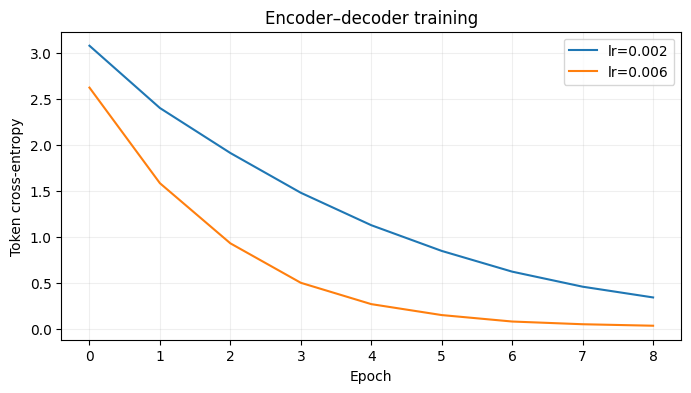

In [5]:
# Tune using validation labels, not held-out target sequences.
def train_model(lr,epochs=9):
 torch.manual_seed(42);m=TinySeq2Seq(len(stoi));opt=torch.optim.AdamW(m.parameters(),lr=lr);trace=[]
 for ep in range(epochs):
    order=np.random.default_rng(ep+123).permutation(len(train_pairs));losses=[]
    m.train()
    for batchids in np.array_split(order,int(np.ceil(len(order)/48))):
      src,dec,y=batch_from([train_pairs[i] for i in batchids]);logits=m(src,dec)
      loss=nn.functional.cross_entropy(logits.reshape(-1,len(stoi)),y.reshape(-1),ignore_index=PAD)
      opt.zero_grad();loss.backward();nn.utils.clip_grad_norm_(m.parameters(),1.);opt.step();losses.append(loss.item())
    trace.append(float(np.mean(losses)))
 return m,trace
def teacher_accuracy(m,pair_list):
 m.eval();src,dec,y=batch_from(pair_list)
 with torch.no_grad():pred=m(src,dec).argmax(-1)
 mask=y!=PAD;return ((pred==y)&mask).sum().item()/mask.sum().item()
runs={}
for lr in [0.002,0.006]:
 m,hist=train_model(lr);runs[lr]=(m,hist,teacher_accuracy(m,valid_pairs[:160]))
print('Validation teacher-forced character accuracy:',{lr:round(v[2],3) for lr,v in runs.items()})
chosen=max(runs,key=lambda lr:runs[lr][2]);model,loss_curve,_=runs[chosen]
for lr,(m,h,acc) in runs.items():plt.plot(h,label=f'lr={lr}')
plt.legend();plt.xlabel('Epoch');plt.ylabel('Token cross-entropy');plt.title('Encoder–decoder training');plt.show()

## 5. Autoregressive inference and final evaluation

At inference, the correct next character is NOT provided. The decoder greedily generates its own previous predictions. This is the more honest evaluation than teacher-forced accuracy.

In [6]:
# Greedy decoding provides a realistic free-running test.
def correct(m,words):
 m.eval();src=pad_list([encode_text(w) for w in words]);generated=torch.full((len(words),1),BOS,dtype=torch.long)
 with torch.no_grad():
  for _ in range(maxlen-1):
    next_id=m(src,generated)[:,-1,:].argmax(-1,keepdim=True)
    generated=torch.cat([generated,next_id],dim=1)
 answers=[]
 for ids in generated[:,1:].tolist():
    out=[]
    for i in ids:
      if i==EOS:break
      if i>=len(special):out.append(itos[i])
    answers.append(''.join(out))
 return answers
subset=test_pairs[:48];preds=correct(model,[p[0] for p in subset]);accuracy=np.mean([p==gold for p,(_,gold) in zip(preds,subset)])
print('Held-out greedy exact match:',round(accuracy,3))
for (bad,truth),guess in list(zip(subset,preds))[:8]:print(f'{bad!r:31} -> {guess!r:31} | target {truth!r}')

Held-out greedy exact match: 0.667
'small dunning shoes'           -> 'small noise g shoes'           | target 'small running shoes'
'small portalbe monitor'        -> 'small portable monitor'        | target 'small portable monitor'
'best wirelses headphones'      -> 'best wireless headphones'      | target 'best wireless headphones'
'new wirelejs headphones'       -> 'new wirelenssheadphones'       | target 'new wireless headphones'
'cheap portzble monitor'        -> 'cheap porte p'                 | target 'cheap portable monitor'
'best lectric toothbrush'       -> 'best electric toothbrush'      | target 'best electric toothbrush'
'small portable monitor'        -> 'small portable monitor'        | target 'small portable monitor'
'comyact gamng laptop'          -> 'compact gaming laptop'         | target 'compact gaming laptop'


## What the results mean / interview discussion

A compact encoder–decoder demonstrates Q/K/V, causal masking and teacher forcing. Query correction is harder than copying clean text; a tiny model trained on a narrow synthetic corpus may underperform a dictionary/edit-distance baseline. Results should be framed as a learning experiment, not production-grade spell correction.

**Try explaining these without looking at the code:**

1. What differs between encoder self-attention, decoder causal attention and cross-attention?
2. Why can teacher-forced accuracy look better than free-running exact match?
3. How would you measure correction impact on search NDCG instead of only spelling?

**Limitations and next step:** Evaluate on a suitably licensed real-world dataset or stronger simulation with domain shift, logging bias and realistic selection. Never treat synthetic performance as production evidence.

## What this project demonstrates, and what it does not

**Next:** break down accuracy by typo type, include unknown brands, increase source length, use beam search and compare latency against edit distance and a dictionary model.

**Reproduce:** `Run All` in Jupyter; no private or uploaded data required. For real data, use leakage-safe train/validation/test partitions and respect each dataset license.

In [7]:
# Show both sequence accuracy and the kinds of mistakes the model makes.
examples = pd.DataFrame({"noisy_query": [r[0] for r in test_pairs],
                         "expected": [r[1] for r in test_pairs],
                         "predicted": correct(model, [r[0] for r in test_pairs])})
examples["exact_match"] = examples.expected == examples.predicted
print("Exact match on truly held-out queries:", round(examples.exact_match.mean(), 3))
print(examples.loc[~examples.exact_match].head(8).to_string(index=False))

Exact match on truly held-out queries: 0.579
                     noisy_query                         expected                     predicted  exact_match
             small dunning shoes              small running shoes           small noise g shoes        False
         new wirelejs headphones          new wireless headphones       new wirelenssheadphones        False
          cheap portzble monitor           cheap portable monitor                 cheap porte p        False
  cheap nnise cancelling earbuds   cheap noise cancelling earbuds cheap nnine cancelling eardsb        False
      compact electric oothbrush      compact electric toothbrush compact electric thboooothble        False
          new electric toothbruh          new electric toothbrush   new electric toooothbrushbr        False
premiuz noise cancelling earbuds premium noise cancelling earbuds premium noise cancelling earb        False
                     new usb cbe                    new usb cable   nest unoerunoe 

**Why free-running evaluation matters:** Training with teacher forcing feeds the true previous character to the decoder. During inference, the model must use its own predictions, and small mistakes can compound across tokens.